# Does a Fed rate hike move the S&P 500?

**An observational study of FOMC decisions, February 1994 to October 2026**
M2 Causal Inference final project, Albert School.

## Data record

This notebook reads one file, `fed_sp500_daily.csv`, which must sit next to the notebook. It downloads nothing, so its results cannot change. Run it with **Restart and Run All**. Install the libraries with `pip install -r requirements.txt` if needed.

| Content | Source | URL | Downloaded |
|---|---|---|---|
| S&P 500 daily closes (the outcome) | Kaggle, *S&P 500 (^GSPC) Historical Data* | https://www.kaggle.com/datasets/paveljurke/s-and-p-500-gspc-historical-data | 2026-11-05 |
| FOMC meeting dates (the treatment dates) | Federal Reserve | https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm | 2026-11-05 |
| Official target rate (the treatment), yields, VIX, credit spread, CPI, unemployment, industrial production | FRED, St. Louis Fed | https://fred.stlouisfed.org (DFEDTAR, DFEDTARU, DFEDTARL, DGS3MO, DGS1, DGS2, DGS10, VIXCLS, BAA, GS10, CPIAUCSL, UNRATE, INDPRO, FEDFUNDS) | 2026-11-05 |
| Foreign stock indices (used only to assess synthetic control) | Yahoo Finance | https://finance.yahoo.com | 2026-11-05 |

The merge is documented in `scripts/build_dataset.py`. It is not needed to run this notebook. Decisions were checked against the Fed's official list of target changes (https://www.federalreserve.gov/monetarypolicy/openmarket.htm): all 92 changes match.

**Disclosure.** An earlier test run looked at several windows and estimators before the plan in `report/analysis_plan.md` was frozen, so the plan is not blind to the data.

In [1]:
import json
import warnings
from pathlib import Path
from statistics import NormalDist

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.tools.sm_exceptions import PerfectSeparationError

SEED = 2026
N_BOOTSTRAP = 2000
N_SIMULATIONS = 500
CONTESTED_BELOW = 0.9  # a hike is "contested" if its propensity is below this
ALPHA = 0.025          # two confirmatory horizons, Bonferroni: 0.05 / 2
DATA_FILE = "fed_sp500_daily.csv"
OUT = Path("../results") if Path("../results").is_dir() else Path("results")
OUT.mkdir(exist_ok=True)
numbers = {}  # every number quoted in the report is saved here

# One colour per group in every figure. Validated for colour-blind separation.
HOLD, HIKE, CUT = "#2a78d6", "#eb6834", "#1baf7a"
INK, SECONDARY, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "axes.titlelocation": "left", "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "text.color": INK,
    "axes.labelcolor": SECONDARY, "xtick.color": SECONDARY, "ytick.color": SECONDARY,
    "lines.linewidth": 1.6, "legend.frameon": False, "legend.fontsize": 8,
})

panel = pd.read_csv(DATA_FILE, parse_dates=["date"])
print("Libraries:", "numpy", np.__version__, "| pandas", pd.__version__, "| statsmodels", statsmodels.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__, "| scikit-learn", sklearn.__version__)
print(f"File: {panel.shape[0]} trading days, {panel.shape[1]} columns, {panel['date'].min().date()} to {panel['date'].max().date()}")
panel.tail(3)

Libraries: numpy 2.5.4 | pandas 3.1.0 | statsmodels 0.15.0 | scipy 1.18.1 | matplotlib 3.11.2 | scikit-learn 1.9.1
File: 11111 trading days, 25 columns, 1982-10-01 to 2026-11-03


,date,sp500_close,fed_target,fomc_decision,fomc_kind,target_change_pp,yield_3m,yield_1y,yield_2y,yield_10y,...,ind_prod_yoy,fedfunds_month_avg,ftse100,dax,cac40,nikkei225,hangseng,asx200,tsx,smi
11108,2026-10-30,7580.07,3.875,NaN,NaN,NaN,4.16,4.36,4.56,4.94,...,2.245,3.88,10729.8,25818.21,7969.42,63290.11,23294.42,8908.1,35620.0,14810.66
11109,2026-11-02,7541.40,3.875,NaN,NaN,NaN,4.21,4.38,4.59,4.91,...,2.245,NaN,10761.3,25981.09,8047.69,63081.86,23393.32,8856.5,35801.1,14802.52
11110,2026-11-03,7568.92,3.875,NaN,NaN,NaN,4.21,4.40,4.61,4.95,...,2.245,NaN,10638.4,25864.62,8020.31,NaN,23525.97,8886.8,35532.3,14743.09


## 1. Question

**In meetings where the Fed raised its target, how different would the S&P 500 return have been if it had held instead?**

- **Unit:** one FOMC decision, February 1994 to October 2026. February 1994 is the first time a decision was announced immediately; before that, markets had to infer decisions.
- **Treatment T:** hike = 1, hold = 0. Cuts are studied separately.
- **Outcome Y:** S&P 500 price return from the close before the decision to one day after it (2-day) and to 21 trading days after it (21-day).
- **Effect wanted:** the ATT, $E[Y(1) - Y(0) \mid T = 1]$. We see $Y(1)$ at hike meetings; $Y(0)$ is the missing world. ATE would ask what a hike would do in a mid-crisis meeting, where it was never on the table and no data exists. The ATT also needs weaker overlap (Session 1, slide 49).

**Why the decision and not the month?** A decision has a date, so we can place controls before it and returns after it. Section 2 shows what goes wrong with monthly averages.

In [2]:
close = panel["sp500_close"].to_numpy()
all_dates = panel["date"].to_numpy()
decision_positions = np.flatnonzero(panel["fomc_decision"].notna().to_numpy())
decision_dates = all_dates[decision_positions]
decision_labels = panel["fomc_decision"].to_numpy()[decision_positions]
HORIZONS = [0, 1, 5, 10, 21, 42, 63]


def window_return(start, end):
    """Percent S&P 500 price return between two trading-day positions."""
    if end >= len(close):
        return np.nan  # the window has not finished yet
    return 100 * (close[end] / close[start] - 1)


def meeting_table(shift=0):
    """One row per FOMC decision.

    The outcome window opens at the close of the day before the decision, and all
    controls are measured at or before that close. `shift` moves the window and the
    controls earlier by that many trading days (for fake-date tests); the treatment
    label does not move.
    """
    rows = []
    for position, label in zip(decision_positions, decision_labels):
        opening = position - shift - 1
        day = panel.iloc[opening]
        as_of = np.datetime64(day["date"])
        known = decision_dates <= as_of
        past_year = known & (decision_dates > as_of - np.timedelta64(365, "D"))
        last_decision = decision_labels[known][-1] if known.any() else "hold"
        row = {
            "date": panel["date"].iloc[position],
            "decision": label,
            "kind": panel["fomc_kind"].iloc[position],
            "change_pp": panel["target_change_pp"].iloc[position],
            # Market expectations
            "spread_3m": day["yield_3m"] - day["fed_target"],
            "spread_1y": day["yield_1y"] - day["fed_target"],
            "spread_2y": day["yield_2y"] - day["fed_target"],
            "change_3m_21d": day["yield_3m"] - panel["yield_3m"].iloc[opening - 21],
            # Policy path
            "prev_hike": int(last_decision == "hike"),
            "prev_cut": int(last_decision == "cut"),
            "hikes_12m": int((decision_labels[past_year] == "hike").sum()),
            "cuts_12m": int((decision_labels[past_year] == "cut").sum()),
            "fed_target": day["fed_target"],
            # The Fed's mandate, last published
            "inflation": day["inflation_yoy"],
            "unemployment": day["unemployment"],
            "unemp_change_3m": day["unemp_change_3m"],
            "ind_prod_yoy": day["ind_prod_yoy"],
            # Market state
            "sp500_ret_21d": window_return(opening - 21, opening),
            "sp500_ret_252d": window_return(opening - 252, opening),
            "vix": day["vix"],
            "credit_spread": day["credit_spread"],
            "term_spread": day["yield_10y"] - day["yield_3m"],
        }
        for horizon in HORIZONS:
            row[f"y{horizon}"] = window_return(opening, opening + 1 + horizon)
        rows.append(row)
    table = pd.DataFrame(rows)
    table["year"] = table["date"].dt.year
    table["hike"] = (table["decision"] == "hike").astype(int)
    table["cut"] = (table["decision"] == "cut").astype(int)
    return table


meetings = meeting_table()
hike_hold = meetings[meetings["decision"].isin(["hike", "hold"])].reset_index(drop=True)
print(meetings["decision"].value_counts().to_string())
assert (meetings["decision"].value_counts()[["hike", "hold", "cut"]].to_list() == [52, 179, 40])

CYCLES = {"1994-95": (1994, 1995), "1997": (1997, 1997), "1999-2000": (1999, 2000), "2004-06": (2004, 2006),
          "2015-18": (2015, 2018), "2022-23": (2022, 2023), "2026": (2026, 2026)}
cycle_table = pd.DataFrame([
    {"Hiking cycle": name, "Hikes": int(hike_hold.loc[hike_hold["year"].between(*years), "hike"].sum()),
     "Holds in those years": int((1 - hike_hold.loc[hike_hold["year"].between(*years), "hike"]).sum())}
    for name, years in CYCLES.items()
])
cycle_table.to_csv(OUT / "table_cycles.csv", index=False)
gaps = pd.Series(decision_positions).diff().shift(-1)
numbers["n_hike"], numbers["n_hold"], numbers["n_cut"] = 52, 179, 40
numbers["median_gap_days"] = float(gaps.median())
example = meetings[meetings["date"] == "2022-03-16"].iloc[0]
numbers["example_y21"], numbers["example_y1"] = float(example["y21"]), float(example["y1"])
numbers["hikes_25bp"] = int((hike_hold.loc[hike_hold["hike"] == 1, "change_pp"].round(2) == 0.25).sum())
numbers["hikes_above_25bp"] = int((hike_hold.loc[hike_hold["hike"] == 1, "change_pp"] > 0.26).sum())
numbers["largest_hike"] = float(hike_hold["change_pp"].max())
numbers["unscheduled_decisions"] = int((meetings["kind"] == "unscheduled").sum())
numbers["share_21d_reach_next"] = float((gaps.dropna() <= 21).mean() * 100)
print(f"Median {gaps.median():.0f} trading days between decisions; {numbers['share_21d_reach_next']:.1f}% of 21-day windows reach the next decision.")
cycle_table

decision
hold    179
hike     52
cut      40
Median 30 trading days between decisions; 4.8% of 21-day windows reach the next decision.


,Hiking cycle,Hikes,Holds in those years
0,1994-95,7,8
1,1997,1,7
2,1999-2000,6,10
3,2004-06,17,7
4,2015-18,9,23
5,2022-23,11,5
6,2026,1,6


## 2. Variables

Each variable has one job, and the causal graph in Section 3 decides it. **Time order is what makes this work: controls come before the decision, and returns come after it.**

| Role | Variables | Rule |
|---|---|---|
| Treatment | Hike vs hold, from the official target | |
| Outcome | S&P 500 return, 2-day and 21-day | Measured after the decision |
| Confounders: market expectations | 3-month, 1-year, 2-year yields minus target; 21-day change in 3-month yield | Adjust, measured the day before |
| Confounders: policy path | Last decision; hikes and cuts in past 12 months; target level | Adjust |
| Confounders: Fed's mandate | Inflation, unemployment and its 3-month change, industrial production, as last published | Adjust |
| Confounders: market state | S&P past 21-day and 252-day return, VIX, credit spread, 10-year minus 3-month yield | Adjust, measured the day before |
| Mediators | Yields, VIX, credit after the decision; later macro data; the next decision | **Never adjust**: they carry the effect |
| Hidden | The Fed's private information; surprise news in the window | Cannot adjust, so we run sensitivity analysis |

In [3]:
EXPECTATIONS = ["spread_3m", "spread_1y", "spread_2y", "change_3m_21d"]
POLICY_PATH = ["prev_hike", "prev_cut", "hikes_12m", "cuts_12m", "fed_target"]
MANDATE = ["inflation", "unemployment", "unemp_change_3m", "ind_prod_yoy"]
MARKET_STATE = ["sp500_ret_21d", "sp500_ret_252d", "vix", "credit_spread", "term_spread"]
CONTROLS = EXPECTATIONS + POLICY_PATH + MANDATE + MARKET_STATE
PROPENSITY = ["spread_3m", "spread_2y", "change_3m_21d", "prev_hike", "inflation", "unemployment",
              "unemp_change_3m", "sp500_ret_21d", "vix"]
PROPENSITY_NO_EXPECTATIONS = ["prev_hike", "hikes_12m", "fed_target", "inflation", "unemployment",
                              "unemp_change_3m", "sp500_ret_21d", "vix"]
LABELS = {
    "spread_3m": "3-month yield minus target", "spread_1y": "1-year yield minus target",
    "spread_2y": "2-year yield minus target", "change_3m_21d": "21-day change, 3-month yield",
    "prev_hike": "Last decision was a hike", "prev_cut": "Last decision was a cut",
    "hikes_12m": "Hikes in past 12 months", "cuts_12m": "Cuts in past 12 months", "fed_target": "Target level",
    "inflation": "Inflation", "unemployment": "Unemployment", "unemp_change_3m": "3-month change, unemployment",
    "ind_prod_yoy": "Industrial production growth", "sp500_ret_21d": "S&P return, past 21 days",
    "sp500_ret_252d": "S&P return, past 252 days", "vix": "VIX", "credit_spread": "Credit spread",
    "term_spread": "10-year minus 3-month yield",
}
assert hike_hold[CONTROLS].isna().sum().sum() == 0

# Why decisions and not months: audit the old monthly labels.
by_month = panel.set_index("date")
month_index = by_month.index.to_period("M")
month_avg = by_month["fedfunds_month_avg"].groupby(month_index).first()
month_end = by_month["sp500_close"].groupby(month_index).last()
month_change = month_avg.diff().round(8)
decision_months = pd.Series(decision_labels, index=pd.DatetimeIndex(decision_dates).to_period("M"))
audit = month_change.loc["2000-01":"2026-10"]
numbers["audit_increase_months"] = int((audit > 0).sum())
numbers["audit_real_hikes"] = int((decision_months[decision_months == "hike"].index >= "2000-01").sum())
since_1994 = month_change.loc["1994-02":"2026-10"]
numbers["audit_months_since_1994"] = int(len(since_1994))
numbers["audit_months_no_decision"] = int((~since_1994.index.isin(decision_months.index)).sum())
print(f"Since 2000 the old monthly rule marks {numbers['audit_increase_months']} 'increase' months; the Fed hiked {numbers['audit_real_hikes']} times.")
print(f"Since 1994, {numbers['audit_months_no_decision']} of {numbers['audit_months_since_1994']} months had no FOMC decision at all.")

monthly_returns = 100 * month_end.pct_change()
old_design = pd.DataFrame({"y": monthly_returns.shift(-1), "up": (month_change > 0).astype(int)}).loc["2000-01":"2026-09"].dropna()
old_fit = smf.ols("y ~ up", data=old_design).fit(cov_type="HC3")
numbers["old_design_est"], numbers["old_design_se"] = float(old_fit.params["up"]), float(old_fit.bse["up"])
print(f"Old design (increase month vs other months, next-month return): {old_fit.params['up']:.2f} (SE {old_fit.bse['up']:.2f})")

# The levels trap: both series trend, so a regression in levels looks strong for no causal reason.
levels = pd.DataFrame({"log_sp500": np.log(month_end), "rate": month_avg, "ret": monthly_returns, "d_rate": month_avg.diff()}).loc["1982-11":"2026-10"].dropna()
levels_fit = smf.ols("log_sp500 ~ rate", data=levels).fit()
changes_fit = smf.ols("ret ~ d_rate", data=levels).fit()
numbers["levels_t"] = float(levels_fit.tvalues["rate"])
numbers["levels_r2"] = float(levels_fit.rsquared)
numbers["levels_dw"] = float(sm.stats.stattools.durbin_watson(levels_fit.resid))
numbers["changes_r2"] = float(changes_fit.rsquared)
print(f"Levels: t = {numbers['levels_t']:.1f}, R2 = {numbers['levels_r2']:.2f}, Durbin-Watson = {numbers['levels_dw']:.3f}. Changes: R2 = {numbers['changes_r2']:.4f}.")

Since 2000 the old monthly rule marks 136 'increase' months; the Fed hiked 41 times.
Since 1994, 126 of 393 months had no FOMC decision at all.
Old design (increase month vs other months, next-month return): -0.15 (SE 0.49)
Levels: t = -18.5, R2 = 0.39, Durbin-Watson = 0.007. Changes: R2 = 0.0000.


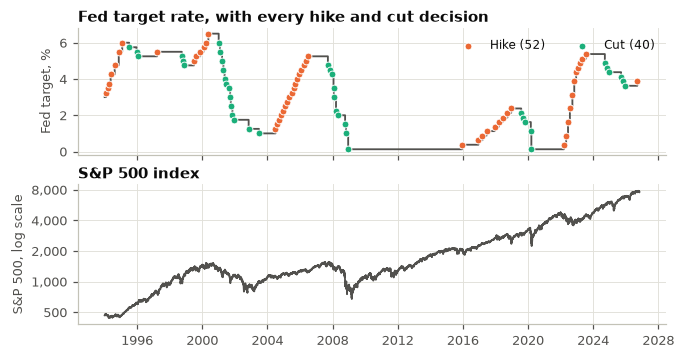

In [4]:
# Figure: the whole sample at a glance. Two panels, because two scales should never share one chart.
sample = panel[panel["date"] >= "1994-01-01"]
fig, axes = plt.subplots(2, 1, figsize=(6.9, 3.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.1], "hspace": 0.22})
axes[0].step(sample["date"], sample["fed_target"], where="post", color=SECONDARY, lw=1.2)
for label, color, name in [("hike", HIKE, "Hike"), ("cut", CUT, "Cut")]:
    chosen = sample[sample["fomc_decision"] == label]
    level_after = sample["fed_target"].shift(-1)[chosen.index]  # the new target takes effect by the next day
    axes[0].scatter(chosen["date"], level_after, s=20, color=color, edgecolor="white", linewidth=0.6, zorder=3, label=f"{name} ({len(chosen)})")
axes[0].set_ylabel("Fed target, %")
axes[0].set_title("Fed target rate, with every hike and cut decision", pad=4)
axes[0].legend(loc="upper right", ncol=2)
axes[1].plot(sample["date"], sample["sp500_close"], color=SECONDARY, lw=1.2)
axes[1].set_yscale("log")
axes[1].set_yticks([500, 1000, 2000, 4000, 8000])
axes[1].set_yticklabels(["500", "1,000", "2,000", "4,000", "8,000"])
axes[1].minorticks_off()
axes[1].set_ylabel("S&P 500, log scale")
axes[1].set_title("S&P 500 index", pad=4)
fig.savefig(OUT / "fig1_timeline.png")
plt.show()

**Reading the audit.** The old monthly rule counts any rise in the monthly average as an "increase", because one hike lifts the average across two months and the rate drifts without any decision. It also puts a mid-month hike's market reaction outside a next-month outcome window. The levels regression looks impressive, but a Durbin-Watson near zero is the classic sign of a spurious regression between two trending series. So we use returns and decisions.

## 3. Method

The guide says to ask in order; the first "yes" wins.

1. **Randomly assigned?** No. The FOMC decides, based on the economy.
2. **Several treated units, before and after?** No. A decision hits the whole index at once. DiD "removes shocks common to both groups" (Session 3), and here the common shock is the effect we want. A sector DiD would answer a different question: relative effects, not the index.
3. **One treated unit, before and after?** It looks like yes, but synthetic control needs one clean intervention and donors the treatment does not touch. The Fed decides eight times a year, so there is no clean "before". The cell below tests the donors. There are also no synthetic control slides in the course folder.
4. **Main confounders observed?** Yes. The Fed's mandate makes the assignment story public: inflation, employment and financial conditions. So this is an **observational study**. Instrumental variables appear in Session 4, but the guide excludes them.

**Key assumption: conditional exchangeability.** Among meetings with the same controls, whether the Fed hiked is unrelated to what the S&P would have done under a hold. Formally, $Y(0) \perp T \mid X$. The data cannot prove this, so Section 6 tries to break it. Angrist, Jorda and Kuersteiner (2018) use the same selection-on-observables logic for FOMC decisions.

In [5]:
DONORS = {"ftse100": "FTSE 100", "dax": "DAX", "cac40": "CAC 40", "nikkei225": "Nikkei 225", "hangseng": "Hang Seng",
          "asx200": "ASX 200", "tsx": "TSX", "smi": "SMI"}
CLOSED_AT_ANNOUNCEMENT = ["ftse100", "dax", "cac40", "nikkei225", "hangseng", "asx200"]  # next-day reaction is clean
donor_months = by_month[["sp500_close"] + list(DONORS)].groupby(month_index).last().loc["1994-02":"2026-10"]
donor_corr = donor_months.pct_change(fill_method=None).corr()["sp500_close"].drop("sp500_close")

scheduled = panel.index[panel["fomc_kind"] == "scheduled"].to_numpy()
sp500_day = panel["sp500_close"].pct_change() * 100
rows = []
for name, label in DONORS.items():
    row = {"Index": label, "Correlation with S&P 500": donor_corr[name]}
    if name in CLOSED_AT_ANNOUNCEMENT:
        foreign = panel[name].dropna().pct_change() * 100
        pairs = pd.DataFrame({
            "foreign": foreign.reindex(scheduled[scheduled + 1 < len(panel)] + 1).to_numpy(),
            "us": sp500_day.reindex(scheduled[scheduled + 1 < len(panel)]).to_numpy(),
        }).dropna()
        fit = smf.ols("foreign ~ us", data=pairs).fit(cov_type="HC3")
        row.update({"Next-day pass-through": fit.params["us"], "t": fit.tvalues["us"], "Meetings": len(pairs)})
    rows.append(row)
donor_table = pd.DataFrame(rows)
donor_table.to_csv(OUT / "table_donors.csv", index=False)
numbers["donor_corr_min"], numbers["donor_corr_max"] = float(donor_corr.min()), float(donor_corr.max())
numbers["donor_pass"] = {r["Index"]: [float(r["Next-day pass-through"]), float(r["t"])] for r in rows if "t" in r}
donor_table.round(2)

,Index,Correlation with S&P 500,Next-day pass-through,t,Meetings
0,FTSE 100,0.75,0.22,2.31,262.0
1,DAX,0.77,0.21,1.71,259.0
2,CAC 40,0.75,0.24,1.92,260.0
3,Nikkei 225,0.60,0.39,3.53,245.0
4,Hang Seng,0.57,0.60,5.27,251.0
5,ASX 200,0.72,0.51,8.49,260.0
6,TSX,0.79,NaN,NaN,NaN
7,SMI,0.68,NaN,NaN,NaN


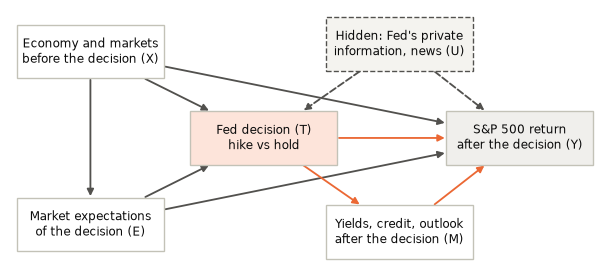

In [6]:
# Figure: the causal graph. An arrow means "changing this could change that".
fig, ax = plt.subplots(figsize=(6.9, 3.0))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
HALF_W, HALF_H = 0.125, 0.105
nodes = {
    "X": (0.135, 0.84, "Economy and markets\nbefore the decision (X)", "white", "-"),
    "E": (0.135, 0.16, "Market expectations\nof the decision (E)", "white", "-"),
    "T": (0.43, 0.50, "Fed decision (T)\nhike vs hold", "#fde4da", "-"),
    "M": (0.66, 0.13, "Yields, credit, outlook\nafter the decision (M)", "white", "-"),
    "Y": (0.865, 0.50, "S&P 500 return\nafter the decision (Y)", "#f0efec", "-"),
    "U": (0.66, 0.87, "Hidden: Fed's private\ninformation, news (U)", "#f4f3ef", "--"),
}
for x, y, text, fill, style in nodes.values():
    ax.add_patch(plt.Rectangle((x - HALF_W, y - HALF_H), 2 * HALF_W, 2 * HALF_H, fc=fill, ec=SECONDARY if style == "--" else AXIS,
                               ls=style, lw=0.9, zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=7.8, zorder=3)


def box_edge(centre, toward):
    """Point where the line from a box centre to another point leaves the box."""
    dx, dy = toward[0] - centre[0], toward[1] - centre[1]
    scale = min(HALF_W / abs(dx) if dx else np.inf, HALF_H / abs(dy) if dy else np.inf)
    return centre[0] + scale * dx, centre[1] + scale * dy


def arrow(a, b, color=SECONDARY, dashed=False):
    start_point, end_point = nodes[a][:2], nodes[b][:2]
    ax.annotate("", xy=box_edge(end_point, start_point), xytext=box_edge(start_point, end_point), zorder=1,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2, ls="--" if dashed else "-", shrinkA=1, shrinkB=1, mutation_scale=9))


for a, b in [("X", "E"), ("X", "T"), ("X", "Y"), ("E", "T"), ("E", "Y")]:
    arrow(a, b)
for a, b in [("T", "Y"), ("T", "M"), ("M", "Y")]:
    arrow(a, b, color=HIKE)
for a, b in [("U", "T"), ("U", "Y")]:
    arrow(a, b, dashed=True)
fig.savefig(OUT / "fig2_dag.png")
plt.show()

**Reading the donor table.** Markets closed at the announcement carry the US decision-day move into their next session: clearly in Asia, more weakly in Europe. Other central banks were also tightening in 2022. So foreign indices are not untouched stand-ins, and synthetic control's key assumption fails. This matches Miranda-Agrippino and Rey (2020), who find that US monetary policy moves risky assets worldwide.

**How to read the graph.** The orange arrows are the effect we want, so we must not block them: controlling for M would remove part of the effect. X and E open back-door paths, so we adjust for them. The dashed paths through U cannot be blocked with data, so we run sensitivity analysis.

**E is the subtle one.** Prices already include what markets expect, so a fully expected hike is not news on the day. A hike and a hold therefore start from different expectations, and that difference hides the effect. Leaving E out biases the estimate toward zero.

## 4. Compare the groups

Before estimating anything: how different are hike meetings from hold meetings, and do comparable meetings exist at all? This is the balance and overlap work of Lab 1.

In [7]:
def fit_propensity(data, columns):
    """Logit model of the chance of a hike, given what was known before the decision."""
    return sm.Logit(data["hike"], sm.add_constant(data[columns])).fit(disp=0, maxiter=200)


def smd(treated, control, control_weights, pooled_sd):
    """Standardised mean difference: the gap between groups in units of standard deviation."""
    return (treated.mean() - np.average(control, weights=control_weights)) / pooled_sd


propensity_model = fit_propensity(hike_hold, PROPENSITY)
hike_hold["e"] = propensity_model.predict(sm.add_constant(hike_hold[PROPENSITY]))
hike_hold["e_no_exp"] = fit_propensity(hike_hold, PROPENSITY_NO_EXPECTATIONS).predict(sm.add_constant(hike_hold[PROPENSITY_NO_EXPECTATIONS]))
hikes, holds = hike_hold[hike_hold["hike"] == 1], hike_hold[hike_hold["hike"] == 0]


def effective_controls(scores):
    """How many hold meetings the weights are really worth (Kish effective sample size)."""
    odds = scores / (1 - scores)
    return float(odds.sum() ** 2 / (odds ** 2).sum())


numbers["auc_with"] = float(roc_auc_score(hike_hold["hike"], hike_hold["e"]))
numbers["auc_without"] = float(roc_auc_score(hike_hold["hike"], hike_hold["e_no_exp"]))
numbers["ess_with"] = effective_controls(holds["e"])
numbers["ess_without"] = effective_controls(holds["e_no_exp"])
numbers["hikes_above_contested"] = int((hikes["e"] >= CONTESTED_BELOW).sum())
numbers["hikes_contested"] = int((hikes["e"] < CONTESTED_BELOW).sum())
numbers["holds_above_half"] = int((holds["e"] > 0.5).sum())
numbers["holds_above_tenth"] = int((holds["e"] > 0.1).sum())
numbers["hikes_above_95"] = int((hikes["e"] > 0.95).sum())
print(f"AUC with market expectations {numbers['auc_with']:.3f}, without {numbers['auc_without']:.3f}")
print(f"Effective hold meetings: with {numbers['ess_with']:.1f}, without {numbers['ess_without']:.1f}")
print(f"Hikes with propensity >= {CONTESTED_BELOW}: {numbers['hikes_above_contested']} of 52. Holds above 0.5: {numbers['holds_above_half']} of 179.")

# Balance: how far apart are the groups, before and after weighting?
pooled_sd = np.sqrt((hikes[CONTROLS].var() + holds[CONTROLS].var()) / 2)
odds = holds["e"] / (1 - holds["e"])
contested_hikes = hikes[hikes["e"] < CONTESTED_BELOW]
contested_holds = holds[holds["e"] < CONTESTED_BELOW]
contested_odds = contested_holds["e"] / (1 - contested_holds["e"])
balance = pd.DataFrame({
    "Variable": [LABELS[c] for c in CONTROLS],
    "Hike mean": hikes[CONTROLS].mean().to_numpy(),
    "Hold mean": holds[CONTROLS].mean().to_numpy(),
    "Gap, raw": [smd(hikes[c], holds[c], np.ones(len(holds)), pooled_sd[c]) for c in CONTROLS],
    "Gap, weighted": [smd(hikes[c], holds[c], odds, pooled_sd[c]) for c in CONTROLS],
    "Gap, contested": [smd(contested_hikes[c], contested_holds[c], contested_odds, pooled_sd[c]) for c in CONTROLS],
})
balance.to_csv(OUT / "table_balance.csv", index=False)
numbers["balance"] = {
    "raw_mean": float(balance["Gap, raw"].abs().mean()), "weighted_mean": float(balance["Gap, weighted"].abs().mean()),
    "contested_mean": float(balance["Gap, contested"].abs().mean()), "raw_max": float(balance["Gap, raw"].abs().max()),
    "weighted_max": float(balance["Gap, weighted"].abs().max()), "contested_max": float(balance["Gap, contested"].abs().max()),
    "n_raw_above_quarter": int((balance["Gap, raw"].abs() > 0.25).sum()),
    "n_contested_above_quarter": int((balance["Gap, contested"].abs() > 0.25).sum()),
}
for var in ["inflation", "unemployment", "spread_3m", "vix"]:
    numbers[f"mean_hike_{var}"], numbers[f"mean_hold_{var}"] = float(hikes[var].mean()), float(holds[var].mean())
balance.round(2)

AUC with market expectations 0.967, without 0.856
Effective hold meetings: with 10.6, without 27.8
Hikes with propensity >= 0.9: 25 of 52. Holds above 0.5: 11 of 179.


,Variable,Hike mean,Hold mean,"Gap, raw","Gap, weighted","Gap, contested"
0,3-month yield minus target,0.32,-0.07,1.84,0.62,-0.14
1,1-year yield minus target,0.75,0.09,1.57,-0.01,-0.58
2,2-year yield minus target,0.97,0.29,1.07,-0.01,-0.36
3,"21-day change, 3-month yield",0.26,0.01,1.52,0.60,-0.13
4,Last decision was a hike,0.60,0.12,1.15,-0.39,-0.58
5,Last decision was a cut,0.00,0.07,-0.38,-0.03,-0.03
6,Hikes in past 12 months,3.88,1.02,1.22,-0.02,-0.17
7,Cuts in past 12 months,0.19,1.11,-0.63,-0.26,-0.22
8,Target level,3.11,2.30,0.39,-0.54,-0.55
9,Inflation,3.72,2.19,0.89,0.41,-0.10


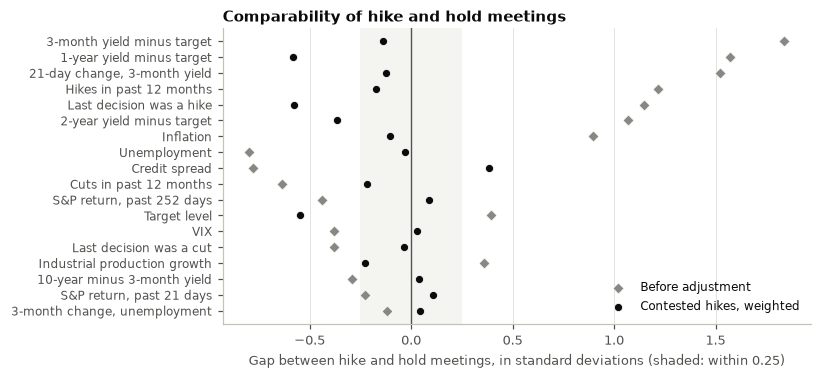

In [8]:
# Figure: balance before and after weighting. Points near zero mean comparable groups.
fig, ax = plt.subplots(figsize=(6.9, 3.5))
order = balance.reindex(balance["Gap, raw"].abs().sort_values().index)
y_positions = np.arange(len(order))
ax.axvline(0, color=SECONDARY, lw=0.9)
ax.axvspan(-0.25, 0.25, color=GRID, alpha=0.35, lw=0)
ax.scatter(order["Gap, raw"], y_positions, s=26, color=MUTED, marker="D", edgecolor="white", linewidth=0.5, zorder=3, label="Before adjustment")
ax.scatter(order["Gap, contested"], y_positions, s=28, color=INK, edgecolor="white", linewidth=0.5, zorder=3, label="Contested hikes, weighted")
ax.set_yticks(y_positions)
ax.set_yticklabels(order["Variable"], fontsize=7.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Gap between hike and hold meetings, in standard deviations (shaded: within 0.25)")
ax.set_title("Comparability of hike and hold meetings", pad=4)
ax.legend(loc="lower right")
fig.savefig(OUT / "fig3_balance.png")
plt.show()

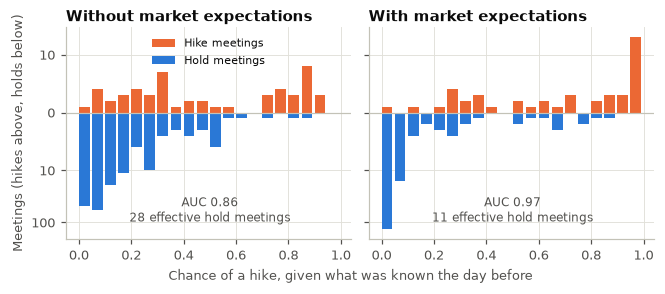

,Chance of a hike,Hikes,Holds,"Gap, 2-day","Gap, 21-day"
0,Below 0.1,1,152,NaN,NaN
1,0.1 to 0.5,12,16,-0.07,-0.63
2,0.5 to 0.9,14,11,-0.06,-1.90
3,0.9 and above,25,0,NaN,NaN


In [9]:
# Figure: overlap. Do comparable hold meetings exist for each hike?
fig, axes = plt.subplots(1, 2, figsize=(6.9, 2.5), sharey=True, gridspec_kw={"wspace": 0.06})
bins = np.linspace(0, 1, 21)
for ax, column, title, auc, ess in [
    (axes[0], "e_no_exp", "Without market expectations", numbers["auc_without"], numbers["ess_without"]),
    (axes[1], "e", "With market expectations", numbers["auc_with"], numbers["ess_with"]),
]:
    up, _ = np.histogram(hikes[column], bins=bins)
    down, _ = np.histogram(holds[column], bins=bins)
    width = (bins[1] - bins[0]) * 0.82
    ax.bar(bins[:-1], up, width=width, align="edge", color=HIKE, label="Hike meetings")
    ax.bar(bins[:-1], -down, width=width, align="edge", color=HOLD, label="Hold meetings")
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_title(title, pad=4)
    ax.set_yscale("symlog", linthresh=10)
    ax.set_yticks([-100, -10, 0, 10])
    ax.set_yticklabels(["100", "10", "0", "10"])
    ax.minorticks_off()
    ax.text(0.5, -60, f"AUC {auc:.2f}\n{ess:.0f} effective hold meetings", fontsize=7.8, color=SECONDARY, va="center", ha="center")
axes[0].set_ylabel("Meetings (hikes above, holds below)")
axes[0].legend(loc="upper center", fontsize=7.5)
fig.supxlabel("Chance of a hike, given what was known the day before", fontsize=8.5, color=SECONDARY, y=-0.05)
fig.savefig(OUT / "fig4_overlap.png")
plt.show()

# Compare like with like: gaps inside bands of similar propensity (the table logic of Session 1).
hike_hold["band"] = pd.cut(hike_hold["e"], [0, 0.1, 0.5, 0.9, 1.0], labels=["Below 0.1", "0.1 to 0.5", "0.5 to 0.9", "0.9 and above"], right=False)
rows = []
for band, group in hike_hold.groupby("band", observed=False):
    in_hikes, in_holds = group[group["hike"] == 1], group[group["hike"] == 0]
    row = {"Chance of a hike": band, "Hikes": len(in_hikes), "Holds": len(in_holds)}
    for y, name in [("y1", "Gap, 2-day"), ("y21", "Gap, 21-day")]:
        enough = len(in_hikes) >= 2 and in_holds[y].notna().sum() >= 2
        row[name] = in_hikes[y].mean() - in_holds[y].mean() if enough else np.nan
    rows.append(row)
strata = pd.DataFrame(rows)
strata.to_csv(OUT / "table_strata.csv", index=False)
numbers["strata"] = json.loads(strata.to_json(orient="records"))
strata.round(2)

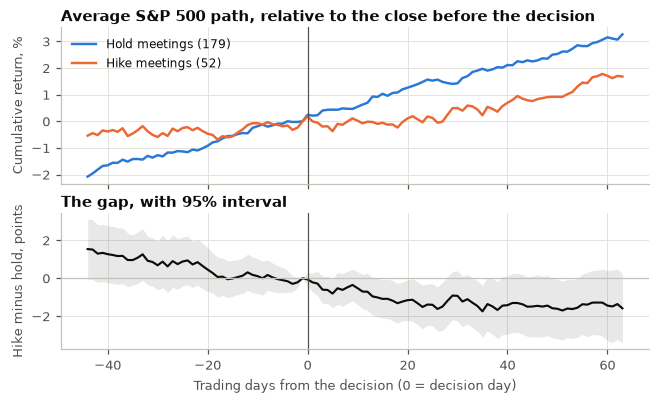

In [10]:
# Figure: the average path of the S&P 500 around each decision. Flat before and a jump after is what a decision effect would look like.
event_times = np.arange(-44, 64)
paths = np.full((len(hike_hold), len(event_times)), np.nan)
date_to_position = {date: position for date, position in zip(decision_dates, decision_positions)}
for row_number, date in enumerate(hike_hold["date"].to_numpy()):
    position = date_to_position[date]
    for column, time in enumerate(event_times):
        if position + time < len(close):
            paths[row_number, column] = 100 * (close[position + time] / close[position - 1] - 1)
is_hike = hike_hold["hike"].to_numpy() == 1
path_hike, path_hold = np.nanmean(paths[is_hike], axis=0), np.nanmean(paths[~is_hike], axis=0)
path_gap = path_hike - path_hold
n_hike_at = (~np.isnan(paths[is_hike])).sum(axis=0)
n_hold_at = (~np.isnan(paths[~is_hike])).sum(axis=0)
path_se = np.sqrt(np.nanvar(paths[is_hike], axis=0, ddof=1) / n_hike_at + np.nanvar(paths[~is_hike], axis=0, ddof=1) / n_hold_at)
gap_at = {int(t): float(g) for t, g in zip(event_times, path_gap)}
numbers["path_gap"] = {str(t): gap_at[t] for t in [-44, -23, -21, -10, -3, 0, 1, 5, 10, 21, 42, 63]}
numbers["path_mean_hike_21"], numbers["path_mean_hold_21"] = float(path_hike[event_times == 21][0]), float(path_hold[event_times == 21][0])

fig, axes = plt.subplots(2, 1, figsize=(6.9, 3.8), sharex=True, gridspec_kw={"height_ratios": [1.15, 1], "hspace": 0.2})
axes[0].plot(event_times, path_hold, color=HOLD, label="Hold meetings (179)")
axes[0].plot(event_times, path_hike, color=HIKE, label="Hike meetings (52)")
axes[0].set_ylabel("Cumulative return, %")
axes[0].set_title("Average S&P 500 path, relative to the close before the decision", pad=4)
axes[0].legend(loc="upper left")
axes[1].fill_between(event_times, path_gap - 1.96 * path_se, path_gap + 1.96 * path_se, color=SECONDARY, alpha=0.13, lw=0)
axes[1].plot(event_times, path_gap, color=INK, lw=1.4)
axes[1].axhline(0, color=AXIS, lw=0.8)
axes[1].set_ylabel("Hike minus hold, points")
axes[1].set_xlabel("Trading days from the decision (0 = decision day)")
axes[1].set_title("The gap, with 95% interval", pad=4)
for ax in axes:
    ax.axvline(0, color=SECONDARY, lw=0.8)
fig.savefig(OUT / "fig5_event_time.png")
plt.show()

## 5. Estimate

We start with the naive gap, then make the comparison fair in three ways. Each one builds the missing world differently.

- **Naive gap:** hike mean minus hold mean. This is the ATT plus selection bias (Session 1, slide 21).
- **Regression (headline):** the guide's recipe, $Y = \alpha + \beta T + X'\gamma + \varepsilon$, with HC3 robust standard errors. By Frisch-Waugh-Lovell (Session 1, slide 45), $\beta$ comes only from the part of the decision that the controls did not predict. So regression leans on contested meetings; here it does not estimate a plain ATT.
- **Standardisation (Session 1, slide 49):** fit the return model on holds only, predict $Y(0)$ for each hike, and average the differences.
- **Inverse-odds weighting (Session 1, slide 50):** give each hold the weight $e/(1-e)$, so that the holds resemble the hikes.

Standardisation and weighting are reported for **all hikes** and for **contested hikes** (propensity below 0.9), where comparable holds exist. Their intervals come from resampling whole calendar years, which keeps shocks within a year together.

**Multiple testing.** There are two confirmatory horizons, so each is tested at 2.5%, and the main table shows 97.5% intervals (Session 2, slide 37).

In [11]:
def add_constant(matrix):
    return np.column_stack([np.ones(len(matrix)), matrix])


def propensity_scores(T, Z):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = sm.Logit(T, Z).fit(disp=0, maxiter=200)
    return np.clip(fit.predict(Z), 1e-6, 1 - 1e-6)


def estimators(T, Y, X, Z):
    """All point estimates at once, from plain arrays so that they can be repeated quickly."""
    hikes_mask, holds_mask = T == 1, T == 0
    scores = propensity_scores(T, Z)
    odds = scores / (1 - scores)
    predicted_hold = X @ np.linalg.lstsq(X[holds_mask], Y[holds_mask], rcond=None)[0]
    contested_hike_mask = hikes_mask & (scores < CONTESTED_BELOW)
    contested_hold_mask = holds_mask & (scores < CONTESTED_BELOW)
    if contested_hike_mask.sum() == 0:
        raise ValueError("No contested hikes in this draw")
    band_gaps, band_sizes = [], []
    for low, high in [(0.1, 0.5), (0.5, CONTESTED_BELOW)]:
        in_band = (scores >= low) & (scores < high)
        if (in_band & hikes_mask).any() and (in_band & holds_mask).any():
            band_gaps.append(Y[in_band & hikes_mask].mean() - Y[in_band & holds_mask].mean())
            band_sizes.append((in_band & hikes_mask).sum())
    if not band_gaps:
        raise ValueError("No band with both hikes and holds in this draw")
    return {
        "Naive gap": Y[hikes_mask].mean() - Y[holds_mask].mean(),
        "Regression": np.linalg.lstsq(np.column_stack([T, X]), Y, rcond=None)[0][0],
        "Standardisation, all hikes": (Y[hikes_mask] - predicted_hold[hikes_mask]).mean(),
        "Weighting, all hikes": Y[hikes_mask].mean() - np.average(Y[holds_mask], weights=odds[holds_mask]),
        "Standardisation, contested": (Y[contested_hike_mask] - predicted_hold[contested_hike_mask]).mean(),
        "Weighting, contested": Y[contested_hike_mask].mean() - np.average(Y[contested_hold_mask], weights=odds[contested_hold_mask]),
        "Within bands, contested": np.average(band_gaps, weights=band_sizes),
    }


def arrays_for(data, y):
    used = data.dropna(subset=[y])
    return (used["hike"].to_numpy(), used[y].to_numpy(), add_constant(used[CONTROLS].to_numpy()),
            add_constant(used[PROPENSITY].to_numpy()), used["year"].to_numpy())


def year_block_bootstrap(data, y, draws=N_BOOTSTRAP, seed=SEED):
    """Resample whole calendar years, then re-estimate everything, including the propensity model."""
    T, Y, X, Z, years = arrays_for(data, y)
    rng = np.random.default_rng(seed)
    unique_years = np.unique(years)
    rows_of_year = {year: np.flatnonzero(years == year) for year in unique_years}
    results, failed = [], 0
    for _ in range(draws):
        chosen = np.concatenate([rows_of_year[year] for year in rng.choice(unique_years, len(unique_years))])
        try:
            estimate = estimators(T[chosen], Y[chosen], X[chosen], Z[chosen])
        except (np.linalg.LinAlgError, PerfectSeparationError, ValueError, ZeroDivisionError):
            failed += 1
            continue
        if all(np.isfinite(value) for value in estimate.values()):
            results.append(estimate)
        else:
            failed += 1
    return pd.DataFrame(results), failed


def regression(data, y, controls=CONTROLS, treatment="hike", cov_type="HC3", cov_kwds=None, extra=""):
    formula = f"{y} ~ {treatment}" + "".join(f" + {c}" for c in controls) + extra
    return smf.ols(formula, data=data).fit(cov_type=cov_type, cov_kwds=cov_kwds)


CONFIRMATORY = {"y1": "2-day", "y21": "21-day"}
rows = []
numbers["regression_bootstrap"] = {}
for y, horizon in CONFIRMATORY.items():
    used = hike_hold.dropna(subset=[y])
    point = estimators(*arrays_for(hike_hold, y)[:4])
    draws, failed = year_block_bootstrap(hike_hold, y)
    numbers[f"bootstrap_failed_{y}"] = failed
    formula_fits = {"Naive gap": smf.ols(f"{y} ~ hike", data=used).fit(cov_type="HC3"), "Regression": regression(used, y)}
    for method, estimate in point.items():
        if method in formula_fits:
            fit = formula_fits[method]
            assert abs(estimate - fit.params["hike"]) < 1e-8  # two routes to one number
            low, high = fit.conf_int(alpha=ALPHA).loc["hike"]
            rows.append({"Horizon": horizon, "Estimator": method, "Estimate": estimate, "Low": low, "High": high, "Interval": "HC3",
                         "SE": fit.bse["hike"], "p": fit.pvalues["hike"], "N": int(fit.nobs)})
        else:
            low, high = np.percentile(draws[method], [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])
            rows.append({"Horizon": horizon, "Estimator": method, "Estimate": estimate, "Low": low, "High": high, "Interval": "Year-block bootstrap"})
    numbers["regression_bootstrap"][horizon] = [float(v) for v in np.percentile(draws["Regression"], [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])]
    hikes_y, holds_y = used.loc[used["hike"] == 1, y], used.loc[used["hike"] == 0, y]
    numbers[f"reg_se_{y}"], numbers[f"reg_p_{y}"] = float(formula_fits["Regression"].bse["hike"]), float(formula_fits["Regression"].pvalues["hike"])
    numbers[f"naive_se_{y}"], numbers[f"naive_p_{y}"] = float(formula_fits["Naive gap"].bse["hike"]), float(formula_fits["Naive gap"].pvalues["hike"])
    # Smallest effect the regression can detect with 80% power at the 2.5% level (Session 2, slide 25).
    numbers[f"mde_{y}"] = float((NormalDist().inv_cdf(1 - ALPHA / 2) + NormalDist().inv_cdf(0.8)) * formula_fits["Regression"].bse["hike"])
    numbers[f"mean_hike_{y}"], numbers[f"mean_hold_{y}"] = float(hikes_y.mean()), float(holds_y.mean())
    numbers[f"sd_{y}"] = float(used[y].std())
main_table = pd.DataFrame(rows)
main_table.to_csv(OUT / "table_main.csv", index=False)
numbers["main"] = {f"{r['Horizon']}|{r['Estimator']}": [float(r["Estimate"]), float(r["Low"]), float(r["High"])] for r in rows}
main_table.round(3)

/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


... (20 outputs left out)

/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))
/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))
/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


/Users/alivakof/Causal_Project/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


,Horizon,Estimator,Estimate,Low,High,Interval,SE,p,N
0,2-day,Naive gap,-0.216,-0.788,0.355,HC3,0.255,0.396,231.0
1,2-day,Regression,-0.312,-1.113,0.490,HC3,0.358,0.384,231.0
2,2-day,"Standardisation, all hikes",-0.698,-1.534,0.340,Year-block bootstrap,NaN,NaN,NaN
3,2-day,"Weighting, all hikes",-0.383,-1.022,0.579,Year-block bootstrap,NaN,NaN,NaN
4,2-day,"Standardisation, contested",-0.378,-1.100,0.640,Year-block bootstrap,NaN,NaN,NaN
5,2-day,"Weighting, contested",-0.287,-1.231,1.016,Year-block bootstrap,NaN,NaN,NaN
6,2-day,"Within bands, contested",-0.065,-1.317,1.166,Year-block bootstrap,NaN,NaN,NaN
7,21-day,Naive gap,-1.134,-2.421,0.153,HC3,0.574,0.048,230.0
8,21-day,Regression,-2.940,-6.013,0.133,HC3,1.371,0.032,230.0
9,21-day,"Standardisation, all hikes",-3.222,-6.863,0.117,Year-block bootstrap,NaN,NaN,NaN


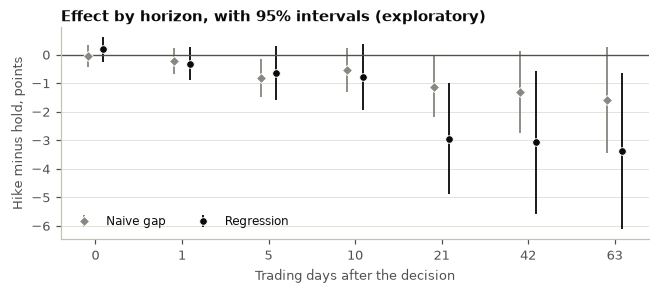

,Trading days after decision,Estimator,Estimate,Low,High,p
0,0,Naive gap,-0.06,-0.45,0.32,0.75
1,0,Regression,0.18,-0.26,0.62,0.42
2,1,Naive gap,-0.22,-0.68,0.25,0.36
3,1,Regression,-0.31,-0.89,0.27,0.29
4,5,Naive gap,-0.81,-1.48,-0.14,0.02
5,5,Regression,-0.65,-1.59,0.29,0.17
6,10,Naive gap,-0.52,-1.30,0.25,0.18
7,10,Regression,-0.77,-1.92,0.37,0.19
8,21,Naive gap,-1.13,-2.20,-0.07,0.04
9,21,Regression,-2.94,-4.89,-0.99,0.00


In [12]:
# Exploratory: the effect across horizons. Windows longer than the gap between meetings overlap, so Newey-West here.
rows = []
for horizon in HORIZONS:
    y = f"y{horizon}"
    used = hike_hold.dropna(subset=[y])
    lags = max(1, int(np.ceil((horizon + 1) / 30)))
    for method, fit in [("Naive gap", smf.ols(f"{y} ~ hike", data=used).fit(cov_type="HAC", cov_kwds={"maxlags": lags})),
                        ("Regression", regression(used, y, cov_type="HAC", cov_kwds={"maxlags": lags}))]:
        low, high = fit.conf_int().loc["hike"]
        rows.append({"Trading days after decision": horizon, "Estimator": method, "Estimate": fit.params["hike"], "Low": low, "High": high, "p": fit.pvalues["hike"]})
dynamic = pd.DataFrame(rows)
dynamic.to_csv(OUT / "table_dynamic.csv", index=False)
numbers["dynamic"] = {f"{int(r['Trading days after decision'])}|{r['Estimator']}": [float(r["Estimate"]), float(r["Low"]), float(r["High"])] for _, r in dynamic.iterrows()}

fig, ax = plt.subplots(figsize=(6.9, 2.5))
positions = np.arange(len(HORIZONS))
for method, color, marker, offset in [("Naive gap", MUTED, "D", -0.09), ("Regression", INK, "o", 0.09)]:
    part = dynamic[dynamic["Estimator"] == method]
    ax.errorbar(positions + offset, part["Estimate"], yerr=[part["Estimate"] - part["Low"], part["High"] - part["Estimate"]],
                fmt=marker, ms=5, color=color, ecolor=color, elinewidth=1.2, capsize=0, mec="white", mew=0.6, label=method)
ax.axhline(0, color=SECONDARY, lw=0.9)
ax.set_xticks(positions)
ax.set_xticklabels([str(h) for h in HORIZONS])
ax.set_xlabel("Trading days after the decision")
ax.set_ylabel("Hike minus hold, points")
ax.set_title("Effect by horizon, with 95% intervals (exploratory)", pad=4)
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", ncol=2)
fig.savefig(OUT / "fig6_dynamic.png")
plt.show()
dynamic.round(2)

## 6. Check

Now we try to break the result, in four ways.

1. **Can the methods find a known truth?** Plant a known effect in simulated data with the real overlap.
2. **Does it change with our choices?** Other controls, subsets, cycles, standard errors, scale.
3. **Does it pass tests it should pass?** Fake dates, future decisions, reshuffled hikes. A real effect of the decision cannot appear before it.
4. **How strong would a hidden confounder have to be?** This is the sensitivity analysis of Session 1, slide 56.

### 6.1 Can the methods find a known truth?

Session 1's habit: *break things on purpose*. We keep the real controls and the real overlap, draw each decision from the fitted propensity, and plant an effect of exactly **-1 point**.

- **Simple world:** returns are linear in the controls.
- **Anticipation world:** the untreated return also rises with the expected chance of a hike, $Y(0) = m(X) + e(X)$. A hold at a meeting where a hike was expected is good news. The size follows Bernanke and Kuttner (2005): about 1% for a surprise 25 bp move.

In [13]:
def hc3_interval(T, Y, X, alpha=ALPHA):
    """HC3 interval for the coefficient on T, without building a formula each time."""
    design = np.column_stack([T, X])
    inverse = np.linalg.pinv(design.T @ design)
    beta = inverse @ design.T @ Y
    residuals = Y - design @ beta
    leverage = np.einsum("ij,jk,ik->i", design, inverse, design)
    meat = design.T @ (design * (residuals / (1 - leverage))[:, None] ** 2)
    se = np.sqrt((inverse @ meat @ inverse)[0, 0])
    critical = NormalDist().inv_cdf(1 - alpha / 2)
    return beta[0] - critical * se, beta[0] + critical * se


def simulate(y, world, true_effect=-1.0, runs=N_SIMULATIONS, seed=SEED):
    T_real, Y_real, X, Z, _ = arrays_for(hike_hold, y)
    rng = np.random.default_rng(seed)
    scores = propensity_scores(T_real, Z)
    holds_mask = T_real == 0
    beta = np.linalg.lstsq(X[holds_mask], Y_real[holds_mask], rcond=None)[0]
    residuals = Y_real[holds_mask] - X[holds_mask] @ beta
    mean_untreated = X @ beta + (scores if world == "Anticipation" else 0)
    results, covered, rejected = [], [], []
    while len(results) < runs:
        T = rng.binomial(1, scores)
        Y = mean_untreated + rng.choice(residuals, size=len(T)) + true_effect * T
        try:
            results.append(estimators(T, Y, X, Z))
        except (np.linalg.LinAlgError, PerfectSeparationError, ValueError, ZeroDivisionError):
            continue
        low, high = hc3_interval(T, Y, X)
        covered.append(low <= true_effect <= high)
        rejected.append(high < 0 or low > 0)
    table = pd.DataFrame(results)
    return pd.DataFrame({
        "Horizon": CONFIRMATORY[y], "World": world, "Estimator": table.columns,
        "Bias": table.mean().to_numpy() - true_effect, "Spread (SD)": table.std().to_numpy(),
        "RMSE": np.sqrt(((table - true_effect) ** 2).mean()).to_numpy(),
    }), float(np.mean(covered)), float(np.mean(rejected))


frames = []
numbers["simulation_coverage"], numbers["simulation_power"] = {}, {}
for y in CONFIRMATORY:
    for world in ["Simple", "Anticipation"]:
        frame, coverage, power = simulate(y, world)
        frames.append(frame)
        numbers["simulation_coverage"][f"{CONFIRMATORY[y]}|{world}"] = coverage
        numbers["simulation_power"][f"{CONFIRMATORY[y]}|{world}"] = power
simulation = pd.concat(frames, ignore_index=True)
simulation.to_csv(OUT / "table_simulation.csv", index=False)
numbers["simulation"] = {f"{r['Horizon']}|{r['World']}|{r['Estimator']}": [float(r["Bias"]), float(r["RMSE"])] for _, r in simulation.iterrows()}
print("Regression interval coverage (target 97.5%):", {k: round(v, 3) for k, v in numbers["simulation_coverage"].items()})
print("Regression power to detect -1 point:", {k: round(v, 3) for k, v in numbers["simulation_power"].items()})
simulation.round(2)

Regression interval coverage (target 97.5%): {'2-day|Simple': 0.974, '2-day|Anticipation': 0.908, '21-day|Simple': 0.98, '21-day|Anticipation': 0.972}
Regression power to detect -1 point: {'2-day|Simple': 0.682, '2-day|Anticipation': 0.346, '21-day|Simple': 0.088, '21-day|Anticipation': 0.046}


,Horizon,World,Estimator,Bias,Spread (SD),RMSE
0,2-day,Simple,Naive gap,0.49,0.23,0.54
1,2-day,Simple,Regression,0.01,0.37,0.37
2,2-day,Simple,"Standardisation, all hikes",0.02,0.47,0.47
3,2-day,Simple,"Weighting, all hikes",0.22,0.64,0.68
4,2-day,Simple,"Standardisation, contested",0.00,0.41,0.41
5,2-day,Simple,"Weighting, contested",0.01,0.53,0.53
6,2-day,Simple,"Within bands, contested",0.03,0.56,0.56
7,2-day,Anticipation,Naive gap,1.17,0.24,1.19
8,2-day,Anticipation,Regression,0.32,0.37,0.49
9,2-day,Anticipation,"Standardisation, all hikes",0.31,0.47,0.56


### 6.2 Does it change with our choices?

Every row below is the regression estimate with one choice changed, shown with a 95% interval. If the answer depended on one arbitrary choice, it would show here.

The **influence** rows were added after the plan was frozen, because dropping just a few windows moved the 21-day result more than expected. Session 2 warns about this: a large sample is not enough if a few units dominate. The headline stays as frozen, and these rows are reported next to it.


Most influential meetings, 2-day:
      date decision    y1  estimate_without
2008-09-16     hold -3.04             -0.19
2023-11-01     hold  2.96             -0.21
2022-11-02     hike -3.53             -0.40
2000-12-19     hold -4.38             -0.24
1994-02-04     hike -1.86             -0.24

Most influential meetings, 21-day:
      date decision    y21  estimate_without
2008-09-16     hold -23.88             -1.91
2015-12-16     hike  -7.93             -2.58
2018-11-08     hold  -6.29             -3.25
2023-09-20     hold  -3.73             -3.16
2023-11-01     hold   9.56             -2.73


/var/folders/sq/hbvm0l9561sg5twm76h4yw3w0000gn/T/ipykernel_10300/1780650975.py:85: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(table.round(2).to_string(index=False))
/var/folders/sq/hbvm0l9561sg5twm76h4yw3w0000gn/T/ipykernel_10300/1780650975.py:85: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(table.round(2).to_string(index=False))


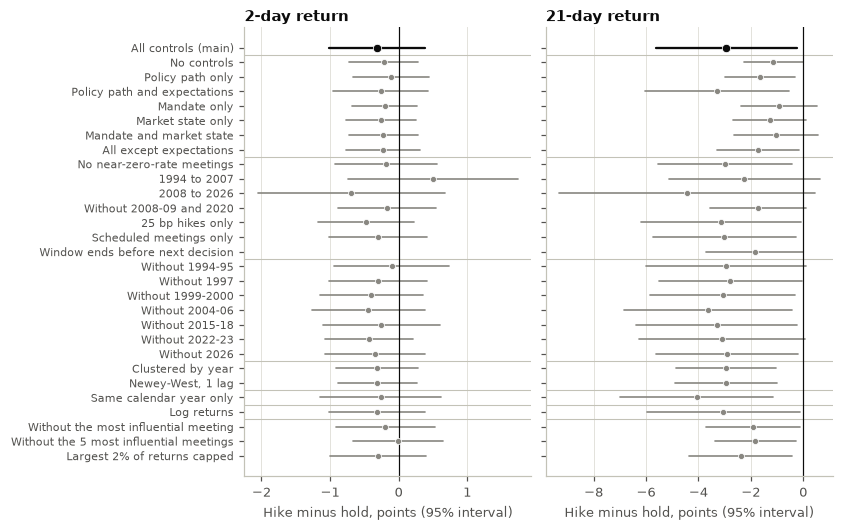

,Group,Check,Outcome,Estimate,Low,High,Hikes,Holds
0,Main,All controls (main),y1,-0.31,-1.01,0.39,52,179
1,Control set,No controls,y1,-0.22,-0.72,0.28,52,179
2,Control set,Policy path only,y1,-0.11,-0.66,0.44,52,179
3,Control set,Policy path and expectations,y1,-0.26,-0.95,0.43,52,179
4,Control set,Mandate only,y1,-0.20,-0.68,0.27,52,179
5,Control set,Market state only,y1,-0.26,-0.77,0.25,52,179
6,Control set,Mandate and market state,y1,-0.22,-0.73,0.29,52,179
7,Control set,All except expectations,y1,-0.23,-0.76,0.31,52,179
8,Subset,No near-zero-rate meetings,y1,-0.18,-0.93,0.57,50,109
9,Subset,1994 to 2007,y1,0.51,-0.73,1.75,31,64


In [14]:
SETS = {
    "No controls": [],
    "Policy path only": POLICY_PATH,
    "Policy path and expectations": POLICY_PATH + EXPECTATIONS,
    "Mandate only": MANDATE,
    "Market state only": MARKET_STATE,
    "Mandate and market state": MANDATE + MARKET_STATE,
    "All except expectations": POLICY_PATH + MANDATE + MARKET_STATE,
}


def usable(controls, data):
    return [c for c in controls if data[c].nunique() > 1]


def check_row(group, label, y, fit, used):
    low, high = fit.conf_int().loc["hike"]
    return {"Group": group, "Check": label, "Outcome": y, "Estimate": fit.params["hike"], "Low": low, "High": high,
            "Hikes": int(used["hike"].sum()), "Holds": int((1 - used["hike"]).sum())}


subset_masks = {
    "No near-zero-rate meetings": hike_hold["fed_target"] > 0.25,
    "1994 to 2007": hike_hold["year"] <= 2007,
    "2008 to 2026": hike_hold["year"] >= 2008,
    "Without 2008-09 and 2020": ~hike_hold["year"].isin([2008, 2009, 2020]),
    "25 bp hikes only": (hike_hold["hike"] == 0) | (hike_hold["change_pp"].round(2) == 0.25),
    "Hikes above 25 bp only": (hike_hold["hike"] == 0) | (hike_hold["change_pp"] > 0.26),
    "Scheduled meetings only": hike_hold["kind"] == "scheduled",
}
next_decision_gap = pd.Series(np.diff(decision_positions, append=10**9), index=decision_dates)
hike_hold["days_to_next"] = next_decision_gap.reindex(hike_hold["date"].to_numpy()).to_numpy()

rows, influence_tables = [], {}
for y in CONFIRMATORY:
    used = hike_hold.dropna(subset=[y])
    rows.append(check_row("Main", "All controls (main)", y, regression(used, y), used))
    for label, controls in SETS.items():
        rows.append(check_row("Control set", label, y, regression(used, y, controls=controls), used))
    for label, mask in subset_masks.items():
        part = used[mask.reindex(used.index)]
        rows.append(check_row("Subset", label, y, regression(part, y, controls=usable(CONTROLS, part)), part))
    if y == "y21":
        part = used[used["days_to_next"] > 21]
        rows.append(check_row("Subset", "Window ends before next decision", y, regression(part, y), part))
    for name, years in CYCLES.items():
        part = used[~used["year"].between(*years)]
        rows.append(check_row("Leave a cycle out", f"Without {name}", y, regression(part, y, controls=usable(CONTROLS, part)), part))
    rows.append(check_row("Standard errors", "Clustered by year", y, regression(used, y, cov_type="cluster", cov_kwds={"groups": used["year"]}), used))
    rows.append(check_row("Standard errors", "Newey-West, 1 lag", y, regression(used, y, cov_type="HAC", cov_kwds={"maxlags": 1}), used))
    rows.append(check_row("Regime", "Same calendar year only", y, regression(used, y, cov_type="cluster", cov_kwds={"groups": used["year"]}, extra=" + C(year)"), used))
    logged = used.assign(log_y=100 * np.log1p(used[y] / 100))
    rows.append(check_row("Scale", "Log returns", y, regression(logged, "log_y"), logged))
    # Influence (added after the plan was frozen, because dropping a few windows moved the 21-day result).
    plain_fit = smf.ols(f"{y} ~ hike + " + " + ".join(CONTROLS), data=used.reset_index(drop=True)).fit()
    change_if_dropped = pd.Series(plain_fit.get_influence().dfbeta[:, list(plain_fit.params.index).index("hike")], index=used.index)
    most_influential = change_if_dropped.abs().sort_values(ascending=False).index
    influence_tables[y] = used.loc[most_influential[:5], ["date", "decision", y]].assign(
        estimate_without=[plain_fit.params["hike"] - change_if_dropped[i] for i in most_influential[:5]])
    numbers[f"influence_{y}"] = {
        "range": [float(plain_fit.params["hike"] - change_if_dropped.max()), float(plain_fit.params["hike"] - change_if_dropped.min())],
        "top_date": str(used.loc[most_influential[0], "date"].date()), "top_decision": used.loc[most_influential[0], "decision"],
        "top_return": float(used.loc[most_influential[0], y]), "top_leverage": float(plain_fit.get_influence().hat_matrix_diag[list(used.index).index(most_influential[0])]),
    }
    part = used.drop(index=most_influential[0])
    assert abs(regression(part, y).params["hike"] - (plain_fit.params["hike"] - change_if_dropped[most_influential[0]])) < 1e-6
    rows.append(check_row("Influence", "Without the most influential meeting", y, regression(part, y), part))
    part = used.drop(index=most_influential[:5])
    rows.append(check_row("Influence", "Without the 5 most influential meetings", y, regression(part, y, controls=usable(CONTROLS, part)), part))
    low_cut, high_cut = used[y].quantile([0.01, 0.99])
    capped = used.assign(capped_y=used[y].clip(low_cut, high_cut))
    rows.append(check_row("Influence", "Largest 2% of returns capped", y, regression(capped, "capped_y"), capped))
checks = pd.DataFrame(rows)
checks.to_csv(OUT / "table_checks.csv", index=False)

leave_one_out = {}
for y in CONFIRMATORY:
    used = hike_hold.dropna(subset=[y])
    estimates = [regression(used, y, controls=[c for c in CONTROLS if c != dropped]).params["hike"] for dropped in CONTROLS]
    leave_one_out[y] = [float(min(estimates)), float(max(estimates))]
numbers["leave_one_control_out"] = leave_one_out
numbers["checks"] = {f"{r['Outcome']}|{r['Check']}": [float(r["Estimate"]), float(r["Low"]), float(r["High"]), int(r["Hikes"]), int(r["Holds"])] for _, r in checks.iterrows()}
for y, table in influence_tables.items():
    print(f"\nMost influential meetings, {CONFIRMATORY[y]}:")
    print(table.round(2).to_string(index=False))

# Figure: all the checks at once.
show = checks[checks["Check"] != "Hikes above 25 bp only"]
labels = list(dict.fromkeys(show.sort_values("Outcome", ascending=False, kind="stable")["Check"]))
labels = [l for g in dict.fromkeys(show["Group"]) for l in labels if l in set(show.loc[show["Group"] == g, "Check"])]
fig, axes = plt.subplots(1, 2, figsize=(6.9, 5.3), sharey=True, gridspec_kw={"wspace": 0.05})
y_positions = np.arange(len(labels))[::-1]
place = dict(zip(labels, y_positions))
group_of = dict(zip(show["Check"], show["Group"]))
for ax, y, title in [(axes[0], "y1", "2-day return"), (axes[1], "y21", "21-day return")]:
    part = show[show["Outcome"] == y]
    for _, row in part.iterrows():
        main = row["Group"] == "Main"
        color = INK if main else MUTED
        ax.plot([row["Low"], row["High"]], [place[row["Check"]]] * 2, color=color, lw=1.5 if main else 1.1, solid_capstyle="round")
        ax.scatter(row["Estimate"], place[row["Check"]], s=30 if main else 16, color=color, edgecolor="white", linewidth=0.5, zorder=3)
    for upper, lower in zip(labels[:-1], labels[1:]):
        if group_of[upper] != group_of[lower]:
            ax.axhline(place[lower] + 0.5, color=AXIS, lw=0.7)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_title(title, pad=4)
    ax.set_xlabel("Hike minus hold, points (95% interval)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(labels, fontsize=7)
fig.savefig(OUT / "fig7_checks.png")
plt.show()
checks.round(2)

### 6.3 Does it pass tests it should pass?

- **Fake date.** Pretend each decision happened one whole window earlier, so the window closes just before the real decision. Controls are measured before the fake window opens. The real decision cannot cause a return before it, so a large gap signals a difference in regimes, or that markets moved in anticipation.
- **Post minus pre.** The return after the decision minus the return in the same-length window before it. This asks whether the gap *changes* at the decision.
- **Lead test.** Add the *next* meeting's hike to the regression. A later decision cannot cause this meeting's return, except through anticipation.
- **Replay the lottery.** Slide the hike sequence along the calendar by every possible distance, which keeps cycles intact. How often does a fake calendar give a gap as large as the real one? This is Fisher's idea from Session 2, slide 38, adapted to a time series.

In [15]:
LENGTHS = {"y1": 2, "y21": 22}  # returns inside each window, so fake dates are exactly one window earlier
rows, numbers["falsification"] = [], {}
for y, horizon in CONFIRMATORY.items():
    used = hike_hold.dropna(subset=[y])
    main_estimate = regression(used, y).params["hike"]
    results = {}
    for windows_back, name in [(1, "Fake date, one window earlier"), (2, "Fake date, two windows earlier")]:
        fake = meeting_table(shift=LENGTHS[y] * windows_back)
        fake = fake[fake["decision"].isin(["hike", "hold"])].dropna(subset=[y])
        naive = smf.ols(f"{y} ~ hike", data=fake).fit(cov_type="HC3")
        adjusted = regression(fake, y)
        rows.append({"Horizon": horizon, "Test": name, "Naive": naive.params["hike"],
                     "Naive low": naive.conf_int(alpha=ALPHA).loc["hike", 0], "Naive high": naive.conf_int(alpha=ALPHA).loc["hike", 1],
                     "Adjusted": adjusted.params["hike"], "Adjusted low": adjusted.conf_int(alpha=ALPHA).loc["hike", 0],
                     "Adjusted high": adjusted.conf_int(alpha=ALPHA).loc["hike", 1]})
        results[name] = rows[-1]
    # Post minus pre: both windows from the same meeting, controls measured before the earlier window opens.
    fake = meeting_table(shift=LENGTHS[y])
    fake = fake[fake["decision"].isin(["hike", "hold"])].reset_index(drop=True)
    fake["post"] = hike_hold[y].to_numpy()
    fake["post_minus_pre"] = fake["post"] - fake[y]
    fake = fake.dropna(subset=["post_minus_pre"])
    naive = smf.ols("post_minus_pre ~ hike", data=fake).fit(cov_type="HC3")
    adjusted = regression(fake, "post_minus_pre")
    rows.append({"Horizon": horizon, "Test": "Post minus pre", "Naive": naive.params["hike"],
                 "Naive low": naive.conf_int(alpha=ALPHA).loc["hike", 0], "Naive high": naive.conf_int(alpha=ALPHA).loc["hike", 1],
                 "Adjusted": adjusted.params["hike"], "Adjusted low": adjusted.conf_int(alpha=ALPHA).loc["hike", 0],
                 "Adjusted high": adjusted.conf_int(alpha=ALPHA).loc["hike", 1]})
    # Lead test: a window should not depend on a decision that comes after it closes.
    decisions_order = pd.Series(decision_labels, index=decision_dates)
    lead = used.copy()
    lead["next_hike"] = (decisions_order.shift(-1).reindex(lead["date"].to_numpy()).to_numpy() == "hike").astype(int)
    lead = lead[lead["date"].to_numpy() != decision_dates[-1]]
    if y == "y21":
        lead = lead[lead["days_to_next"] > 21]
    lead_fit = regression(lead, y, extra=" + next_hike")
    lead_naive = smf.ols(f"{y} ~ hike + next_hike", data=lead).fit(cov_type="HC3")
    rows.append({"Horizon": horizon, "Test": "Lead test: next meeting's hike", "Naive": lead_naive.params["next_hike"],
                 "Naive low": lead_naive.conf_int(alpha=ALPHA).loc["next_hike", 0], "Naive high": lead_naive.conf_int(alpha=ALPHA).loc["next_hike", 1],
                 "Adjusted": lead_fit.params["next_hike"], "Adjusted low": lead_fit.conf_int(alpha=ALPHA).loc["next_hike", 0],
                 "Adjusted high": lead_fit.conf_int(alpha=ALPHA).loc["next_hike", 1]})
    numbers[f"lead_{y}"] = {"current": float(lead_fit.params["hike"]), "next": float(lead_fit.params["next_hike"]), "next_p": float(lead_fit.pvalues["next_hike"]), "n": int(lead_fit.nobs)}
    # Replay the lottery: every circular shift of the hike sequence.
    T, Y, X, _, _ = arrays_for(hike_hold, y)
    Q, _ = np.linalg.qr(X)
    residual = lambda v: v - Q @ (Q.T @ v)
    Y_residual = residual(Y)
    adjusted_gap = lambda t: (residual(t) @ Y_residual) / (residual(t) @ residual(t))
    naive_gap = lambda t: Y[t == 1].mean() - Y[t == 0].mean()
    shifted = [np.roll(T, k) for k in range(1, len(T))]
    observed_adjusted, observed_naive = adjusted_gap(T.astype(float)), naive_gap(T)
    assert abs(observed_adjusted - main_estimate) < 1e-8
    numbers[f"replay_{y}"] = {
        "adjusted_p": float(np.mean([abs(adjusted_gap(t.astype(float))) >= abs(observed_adjusted) for t in shifted])),
        "naive_p": float(np.mean([abs(naive_gap(t)) >= abs(observed_naive) for t in shifted])),
        "shifts": len(shifted),
    }
falsification = pd.DataFrame(rows)
falsification.to_csv(OUT / "table_falsification.csv", index=False)
for _, r in falsification.iterrows():
    numbers["falsification"][f"{r['Horizon']}|{r['Test']}"] = {k: float(r[k]) for k in ["Naive", "Naive low", "Naive high", "Adjusted", "Adjusted low", "Adjusted high"]}
print("Replay the lottery:", {y: numbers[f"replay_{y}"] for y in CONFIRMATORY})
print("Lead test:", {y: numbers[f"lead_{y}"] for y in CONFIRMATORY})
falsification.round(2)

Replay the lottery: {'y1': {'adjusted_p': 0.18695652173913044, 'naive_p': 0.34347826086956523, 'shifts': 230}, 'y21': {'adjusted_p': 0.004366812227074236, 'naive_p': 0.048034934497816595, 'shifts': 229}}
Lead test: {'y1': {'current': -0.29492897129872053, 'next': -0.03219227110429948, 'next_p': 0.9238832575387337, 'n': 230}, 'y21': {'current': -1.8453642640317391, 'next': -0.15017927639684164, 'next_p': 0.8294823718124424, 'n': 226}}


,Horizon,Test,Naive,Naive low,Naive high,Adjusted,Adjusted low,Adjusted high
0,2-day,"Fake date, one window earlier",0.30,-0.19,0.79,0.37,-0.30,1.05
1,2-day,"Fake date, two windows earlier",-0.19,-0.78,0.39,0.03,-0.76,0.82
2,2-day,Post minus pre,-0.52,-1.20,0.17,-0.60,-1.50,0.31
3,2-day,Lead test: next meeting's hike,-0.02,-0.53,0.48,-0.03,-0.79,0.72
4,21-day,"Fake date, one window earlier",-0.78,-2.17,0.61,0.22,-1.54,1.99
5,21-day,"Fake date, two windows earlier",-0.94,-2.42,0.54,1.01,-1.01,3.02
6,21-day,Post minus pre,-0.34,-2.20,1.52,-1.91,-4.42,0.61
7,21-day,Lead test: next meeting's hike,0.26,-1.05,1.57,-0.15,-1.71,1.41


### 6.4 How strong would a hidden confounder have to be?

The omitted-variable formula of Session 1 says bias depends on how strongly the hidden factor relates to treatment and to the outcome. The **robustness value** (Cinelli and Hazlett, 2020) turns this into one number: the share of leftover variation in *both* T and Y that a hidden confounder must explain to bring the estimate to zero. To judge whether that is large, we compare it with what the observed controls explain.

In [16]:
def robustness_value(t_stat, df, alpha=None):
    f = abs(t_stat) / np.sqrt(df)
    if alpha is not None:
        f = f - stats.t.ppf(1 - alpha / 2, df - 1) / np.sqrt(df - 1)
        if f <= 0:
            return 0.0
    return 0.5 * (np.sqrt(f ** 4 + 4 * f ** 2) - f ** 2)


assert abs(robustness_value(4.18445, 783) - 0.1388) < 0.0002  # published Darfur example in Cinelli and Hazlett (2020)
rows, numbers["sensitivity"] = [], {}
for y, horizon in CONFIRMATORY.items():
    used = hike_hold.dropna(subset=[y])
    outcome_fit = smf.ols(f"{y} ~ hike + " + " + ".join(CONTROLS), data=used).fit()
    treatment_fit = smf.ols("hike ~ " + " + ".join(CONTROLS), data=used).fit()
    t_stat, df = outcome_fit.tvalues["hike"], outcome_fit.df_resid
    partial_outcome = {c: outcome_fit.tvalues[c] ** 2 / (outcome_fit.tvalues[c] ** 2 + outcome_fit.df_resid) for c in CONTROLS}
    partial_treatment = {c: treatment_fit.tvalues[c] ** 2 / (treatment_fit.tvalues[c] ** 2 + treatment_fit.df_resid) for c in CONTROLS}
    numbers["sensitivity"][horizon] = {
        "t": float(t_stat), "df": float(df),
        "r2_treatment_on_outcome": float(t_stat ** 2 / (t_stat ** 2 + df)),
        "rv_to_zero": float(robustness_value(t_stat, df)),
        "rv_to_insignificant": float(robustness_value(t_stat, df, alpha=ALPHA)),
        "max_outcome": float(max(partial_outcome.values())), "max_outcome_name": LABELS[max(partial_outcome, key=partial_outcome.get)],
        "max_treatment": float(max(partial_treatment.values())), "max_treatment_name": LABELS[max(partial_treatment, key=partial_treatment.get)],
    }
    rows.extend({"Horizon": horizon, "Control": LABELS[c], "Partial R2 with outcome": partial_outcome[c], "Partial R2 with treatment": partial_treatment[c]} for c in CONTROLS)
benchmarks = pd.DataFrame(rows)
benchmarks.to_csv(OUT / "table_benchmarks.csv", index=False)
print(json.dumps(numbers["sensitivity"], indent=1))

{
 "2-day": {
  "t": -0.8377928293152113,
  "df": 211.0,
  "r2_treatment_on_outcome": 0.0033154961546362017,
  "rv_to_zero": 0.05603675192954503,
  "rv_to_insignificant": 0.0,
  "max_outcome": 0.022982695021627548,
  "max_outcome_name": "21-day change, 3-month yield",
  "max_treatment": 0.06812256551963783,
  "max_treatment_name": "Hikes in past 12 months"
 },
 "21-day": {
  "t": -3.1864599525569988,
  "df": 210.0,
  "r2_treatment_on_outcome": 0.04612021059240425,
  "rv_to_zero": 0.19703651411036927,
  "rv_to_insignificant": 0.06172277838162087,
  "max_outcome": 0.0437062337211515,
  "max_outcome_name": "Cuts in past 12 months",
  "max_treatment": 0.05998667903588104,
  "max_treatment_name": "Hikes in past 12 months"
 }
}


### 6.5 Exploratory, not confirmatory

These results can suggest questions, but they do not count as evidence on their own. **Cuts** are the firefighters of the opening deck: they arrive where the fire is, so a raw comparison mostly shows the fire.

In [17]:
rows = []
cut_hold = meetings[meetings["decision"].isin(["cut", "hold"])].reset_index(drop=True)
numbers["cut_auc"] = float(roc_auc_score(cut_hold["cut"], sm.Logit(cut_hold["cut"], sm.add_constant(cut_hold[EXPECTATIONS + MANDATE + ["vix"]])).fit(disp=0, maxiter=200).predict(sm.add_constant(cut_hold[EXPECTATIONS + MANDATE + ["vix"]]))))
for y, horizon in CONFIRMATORY.items():
    used = cut_hold.dropna(subset=[y])
    naive = smf.ols(f"{y} ~ cut", data=used).fit(cov_type="HC3")
    adjusted = regression(used, y, treatment="cut")
    rows.append({"Horizon": horizon, "Comparison": "Cut vs hold", "Naive": naive.params["cut"], "Naive SE": naive.bse["cut"],
                 "Regression": adjusted.params["cut"], "Regression SE": adjusted.bse["cut"], "N treated": int(used["cut"].sum())})
    part = hike_hold.dropna(subset=[y])
    predicted = smf.ols(f"{y} ~ " + " + ".join(CONTROLS), data=part[part["hike"] == 0]).fit().predict(part)
    gaps = (part[y] - predicted)[part["hike"] == 1]
    groups = pd.cut(part.loc[part["hike"] == 1, "e"], [0, 0.5, 0.9, 1.0], labels=["below 0.5", "0.5 to 0.9", "0.9 and above"], right=False)
    for group, values in gaps.groupby(groups, observed=False):
        rows.append({"Horizon": horizon, "Comparison": f"Hikes with propensity {group} vs predicted hold", "Regression": values.mean(),
                     "Regression SE": values.std() / np.sqrt(len(values)), "N treated": len(values)})
exploratory = pd.DataFrame(rows)
exploratory.to_csv(OUT / "table_exploratory.csv", index=False)
numbers["exploratory"] = json.loads(exploratory.to_json(orient="records"))
exploratory.round(2)

,Horizon,Comparison,Naive,Naive SE,Regression,Regression SE,N treated
0,2-day,Cut vs hold,-0.06,0.48,-0.55,0.67,40
1,2-day,Hikes with propensity below 0.5 vs predicted hold,NaN,NaN,-0.38,0.40,13
2,2-day,Hikes with propensity 0.5 to 0.9 vs predicted ...,NaN,NaN,-0.38,0.33,14
3,2-day,Hikes with propensity 0.9 and above vs predict...,NaN,NaN,-1.04,0.38,25
4,21-day,Cut vs hold,-1.30,1.00,-1.09,1.87,40
5,21-day,Hikes with propensity below 0.5 vs predicted hold,NaN,NaN,-2.00,1.05,13
6,21-day,Hikes with propensity 0.5 to 0.9 vs predicted ...,NaN,NaN,-3.33,1.11,14
7,21-day,Hikes with propensity 0.9 and above vs predict...,NaN,NaN,-3.80,0.72,25


## 7. Conclude

The rule for claiming a causal effect was frozen in `report/analysis_plan.md` before the final run. An effect counts as credibly detected only if all four conditions hold. The first cell below applies the rule and states the result in numbers. The second saves every number the report quotes.

In [18]:
numbers["rule"] = {}
for y, horizon in CONFIRMATORY.items():
    main = numbers["main"]
    reg_est, reg_low, reg_high = main[f"{horizon}|Regression"]
    std_est, std_low, std_high = main[f"{horizon}|Standardisation, contested"]
    wgt_est, wgt_low, wgt_high = main[f"{horizon}|Weighting, contested"]
    fake = numbers["falsification"][f"{horizon}|Fake date, one window earlier"]
    lead = numbers[f"lead_{y}"]
    excludes_zero = lambda low, high: low > 0 or high < 0
    conditions = {
        "1. Regression interval excludes zero": bool(excludes_zero(reg_low, reg_high)),
        "2. Contested estimators agree in sign and one excludes zero": bool(
            np.sign(std_est) == np.sign(reg_est) == np.sign(wgt_est)
            and (excludes_zero(std_low, std_high) or excludes_zero(wgt_low, wgt_high))),
        "3. Fake date is clean": bool(not excludes_zero(fake["Adjusted low"], fake["Adjusted high"]) and abs(fake["Adjusted"]) < 0.5 * abs(reg_est)),
        "4. Lead test is clean": bool(lead["next_p"] >= ALPHA and abs(lead["next"]) < 0.5 * abs(reg_est)),
    }
    numbers["rule"][horizon] = {**conditions, "claim_causal": all(conditions.values())}
    print(f"\n{horizon}: regression {reg_est:.2f} [{reg_low:.2f}, {reg_high:.2f}]")
    for name, passed in conditions.items():
        print(f"  {'PASS' if passed else 'FAIL'}  {name}")
    print("  => causal effect credibly detected:", all(conditions.values()))

def interval(key):
    estimate, low, high = numbers["main"][key]
    return f"{estimate:+.2f} [{low:+.2f}, {high:+.2f}]"


print("\nAnswer, in points of S&P 500 return, hike minus hold, with 97.5% intervals:")
for horizon in CONFIRMATORY.values():
    print(f"\n{horizon}")
    for method in ["Naive gap", "Regression", "Standardisation, all hikes", "Weighting, all hikes",
                   "Standardisation, contested", "Weighting, contested", "Within bands, contested"]:
        print(f"  {method:29s} {interval(f'{horizon}|{method}')}")
print(f"\nThe smallest effect the regression can reliably detect: {numbers['mde_y1']:.1f} points at 2 days, {numbers['mde_y21']:.1f} points at 21 days.")
without_top = numbers["checks"]["y21|Without the most influential meeting"]
print(f"Without one meeting ({numbers['influence_y21']['top_date']}, a {numbers['influence_y21']['top_decision']} followed by {numbers['influence_y21']['top_return']:.1f}%), the 21-day regression is {without_top[0]:.2f}.")


2-day: regression -0.31 [-1.11, 0.49]
  FAIL  1. Regression interval excludes zero
  FAIL  2. Contested estimators agree in sign and one excludes zero
  FAIL  3. Fake date is clean
  PASS  4. Lead test is clean
  => causal effect credibly detected: False

21-day: regression -2.94 [-6.01, 0.13]
  FAIL  1. Regression interval excludes zero
  FAIL  2. Contested estimators agree in sign and one excludes zero
  PASS  3. Fake date is clean
  PASS  4. Lead test is clean
  => causal effect credibly detected: False

Answer, in points of S&P 500 return, hike minus hold, with 97.5% intervals:

2-day
  Naive gap                     -0.22 [-0.79, +0.36]
  Regression                    -0.31 [-1.11, +0.49]
  Standardisation, all hikes    -0.70 [-1.53, +0.34]
  Weighting, all hikes          -0.38 [-1.02, +0.58]
  Standardisation, contested    -0.38 [-1.10, +0.64]
  Weighting, contested          -0.29 [-1.23, +1.02]
  Within bands, contested       -0.06 [-1.32, +1.17]

21-day
  Naive gap             

### What we can and cannot say

Lab 1 ends by asking which statement you would sign.

1. *"Hike meetings were followed by lower S&P 500 returns than hold meetings."* **Yes**, as a description. The raw gap is small at 2 days and about one point at 21 days.
2. *"After adjustment, hikes were associated with lower 21-day returns among comparable meetings."* **Yes**, this is the strongest statement the evidence supports. Every estimator is negative, but the size is uncertain.
3. *"Hikes caused the S&P 500 to fall by exactly X points."* **No.** The result fails our pre-set rule at both horizons.

### Limits

- **Markets anticipate.** The decision is close to predictable the day before, so about half of all hikes have no comparable hold. For those hikes, any estimate is an extrapolation.
- **We measure the decision, not the whole tightening.** Returns start the day before the decision, so what markets priced earlier in the cycle is not counted. Measuring surprises directly would need fed funds futures data.
- **Hidden confounding remains possible.** The Fed may know things that markets do not (the "information effect"), and other news arrives inside a 21-day window.
- **A hold is not one treatment.** Holds near zero rates came with quantitative easing and forward guidance, and hikes range from 25 to 75 basis points.
- **Few independent episodes.** There are 52 hikes but only seven hiking cycles, and one crisis meeting moves the 21-day regression substantially.
- **Revised data.** Macro values respect publication dates but use today's revised figures. Returns exclude dividends.

### Recommendation

Do not treat an announced hike as a signal to trade or to change plans on the day: the average decision has no detectable immediate effect. For planning, treat a lower return of a few points in the month after a hike as a stress scenario, not a forecast. Spend attention on how far a decision differs from what markets expected, because that is where the literature finds the effect, and this design cannot measure it directly.

In [19]:
with open(OUT / "numbers.json", "w") as handle:
    json.dump(numbers, handle, indent=1, default=float)
print(f"Saved {len(list(OUT.iterdir()))} files to {OUT}")

Saved 20 files to ../results
